In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

from sklearn.model_selection import GridSearchCV

df = pd.read_csv('databasev4_2.csv')

X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
X = X.drop(columns=na)

Y = df['pos_y']

X_train, X_test, y_train, y_test, = train_test_split(X,Y,test_size=0.2,random_state=42)

model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.1, epsilon=0.01, gamma=0.01))])


In [ ]:
param_grid = {
    'svr__C': [0.05, 0.1, 0.2, 1, 10, 100, 1000],
    'svr__epsilon': [0.01, 0.05,  0.1, 0.2, 0.5, 1],
    'svr__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)

best_model = grid.best_estimator_

Fitting 5 folds for each of 252 candidates, totalling 1260 fits
Melhores parâmetros: {'svr__C': 0.05, 'svr__epsilon': 0.01, 'svr__gamma': 0.01}


In [12]:
model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.05, epsilon=0.01, gamma=0.01))])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('R²:', r2_score(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('MAE:', mean_absolute_error(y_test, y_pred))

R²: 0.7781165758937189
RMSE: 0.007097644580072106
MAE: 0.005659172224689234


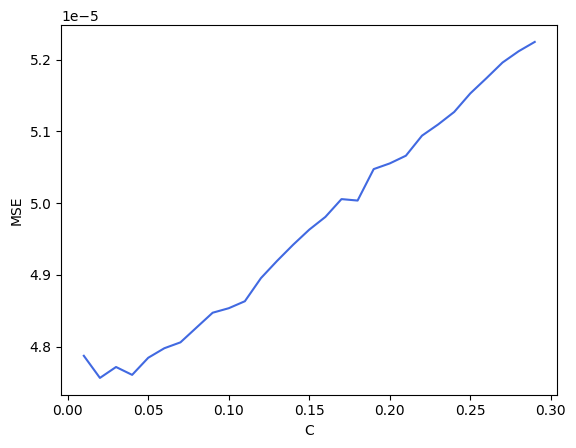

In [ ]:
mse = []
for c in np.arange(0.01,0.3,0.01):
    model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=c, epsilon=0.004, gamma=0.02))])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse.append(mean_squared_error(y_test, y_pred))

fig, ax = plt.subplots(1,1)
plt.xlabel('C')
plt.ylabel('MSE')
plt.plot(np.arange(0.01,0.3,0.01),mse,color='royalblue')
plt.show()

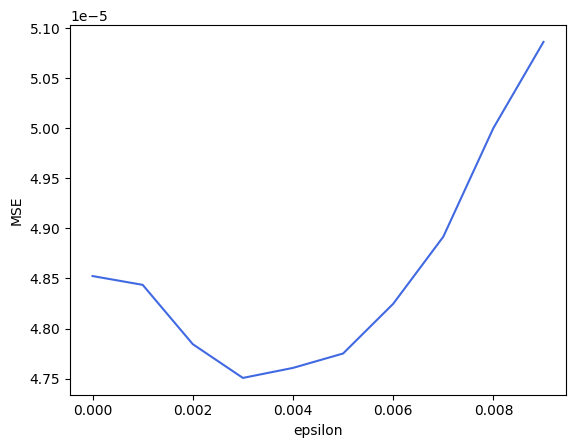

In [ ]:
mse = []
for eps in np.arange(0,0.01,0.001):
    model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.04, epsilon=eps, gamma=0.02))])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse.append(mean_squared_error(y_test, y_pred))
    
fig, ax = plt.subplots(1,1)
plt.xlabel('epsilon')
plt.ylabel('MSE')
plt.plot(np.arange(0,0.01,0.001),mse,color='royalblue')
plt.show()

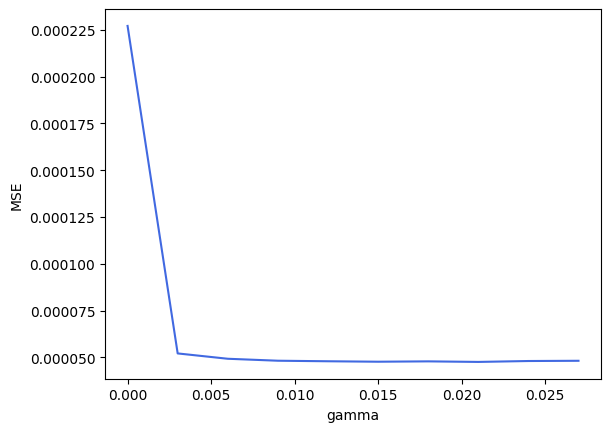

In [ ]:
mse = []
for gamma in np.arange(0,0.03,0.003):
    model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.04, epsilon=0.004, gamma=gamma))])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse.append(mean_squared_error(y_test, y_pred))

fig, ax = plt.subplots(1,1)
plt.xlabel('gamma')
plt.ylabel('MSE')
plt.plot(np.arange(0,0.03,0.003),mse,color='royalblue')
plt.show()

In [ ]:
model = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.04, epsilon=0.004, gamma=0.015))])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('R²:', r2_score(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('MAE:', mean_absolute_error(y_test, y_pred))

ma = mean_absolute_error(y_test, y_pred)*1000

print(f'\nMAE = {ma:.1f} mm ')

R²: 0.7902210527267274
RMSE: 0.006901329596634918
MAE: 0.005389628709385585

MAE = 5.4 mm 
